🚀 Mencoba visualisasi...


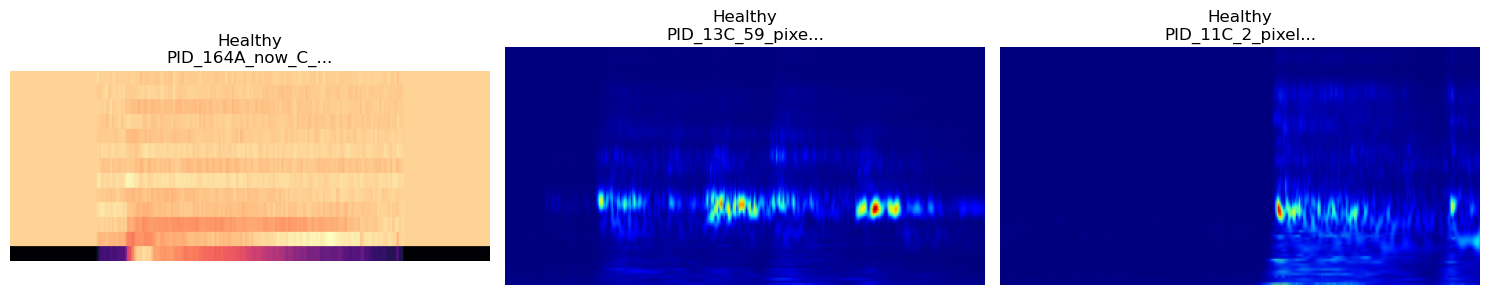

In [1]:
import os
# Fix untuk mencegah Kernel Crash di Windows
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
import random
import matplotlib.pyplot as plt
from PIL import Image

# Memastikan gambar tampil di dalam notebook
%matplotlib inline 

# Definisi ulang path
DATA_DIR = r'C:\TBC SCREENING PENELITIAN\RespiScan_Train_Ready'

def plot_samples_safe(base_path, split='TRAIN', class_name='Healthy', num_samples=3):
    folder = os.path.join(base_path, split, class_name)
    
    # Cek apakah folder ada
    if not os.path.exists(folder):
        print(f"⚠️ Folder tidak ditemukan: {folder}")
        return

    valid_ext = ('.png', '.jpg', '.jpeg')
    all_files = [f for f in os.listdir(folder) if f.lower().endswith(valid_ext)]
    
    if not all_files:
        print(f"⚠️ Tidak ditemukan gambar di: {folder}")
        return

    samples = random.sample(all_files, min(num_samples, len(all_files)))
    
    # Gunakan plt.subplots agar lebih stabil
    fig, axes = plt.subplots(1, len(samples), figsize=(15, 5))
    
    # Jika cuma 1 sampel, buat jadi list agar bisa di-loop
    if len(samples) == 1: axes = [axes]
    
    for i, file in enumerate(samples):
        img_path = os.path.join(folder, file)
        img = Image.open(img_path)
        axes[i].imshow(img)
        axes[i].set_title(f"{class_name}\n{file[:15]}...")
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.show()

# Jalankan test
print("🚀 Mencoba visualisasi...")
plot_samples_safe(DATA_DIR, 'TRAIN', 'Healthy')
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")



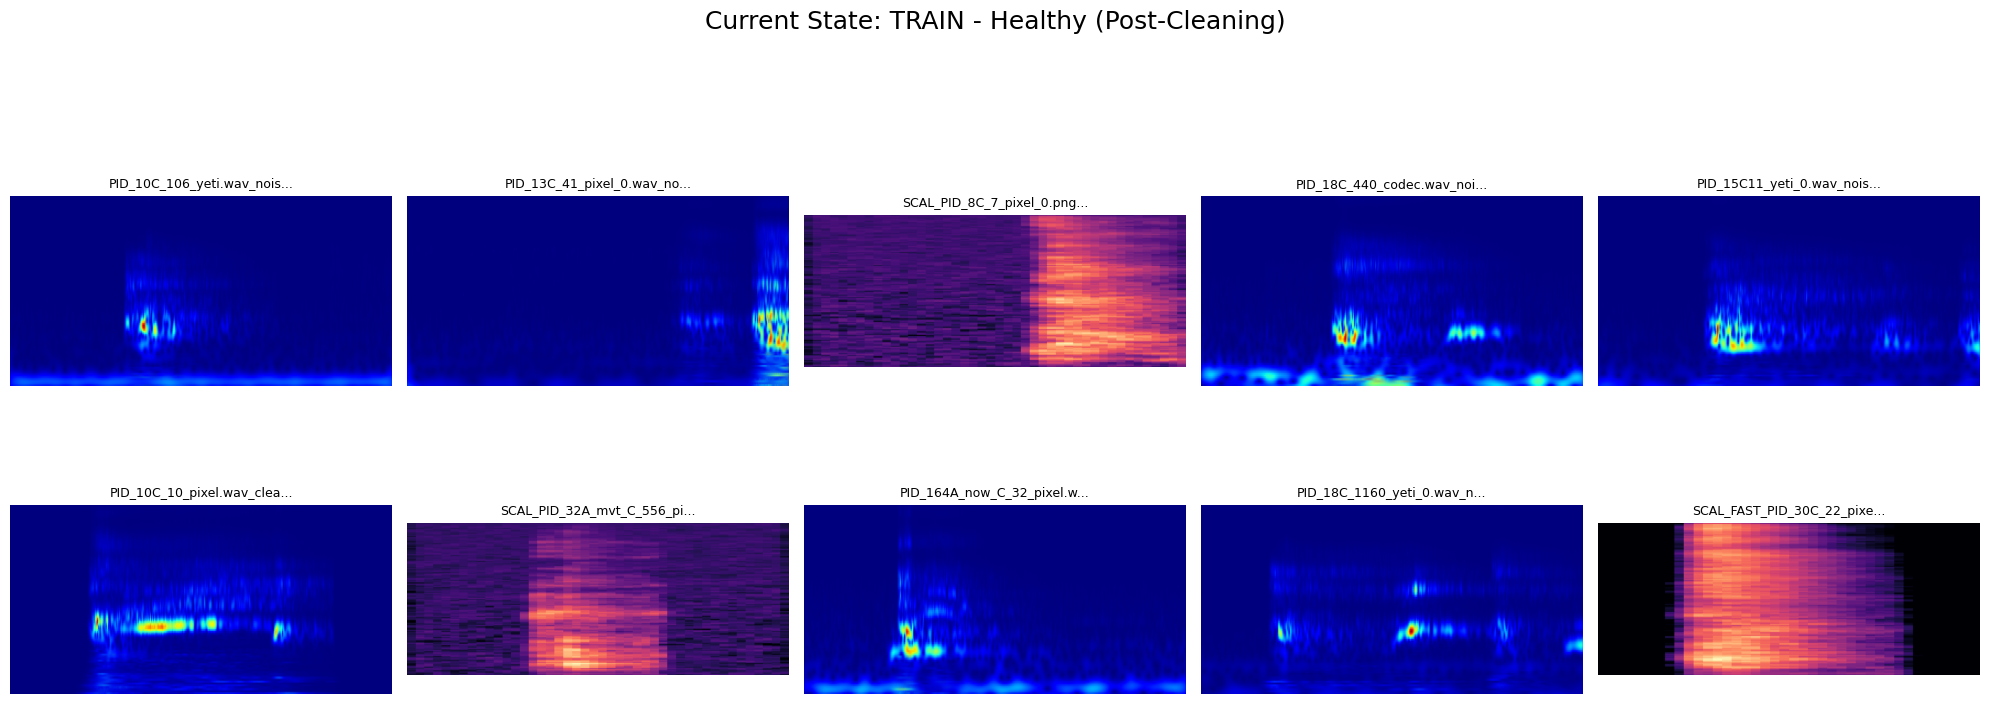

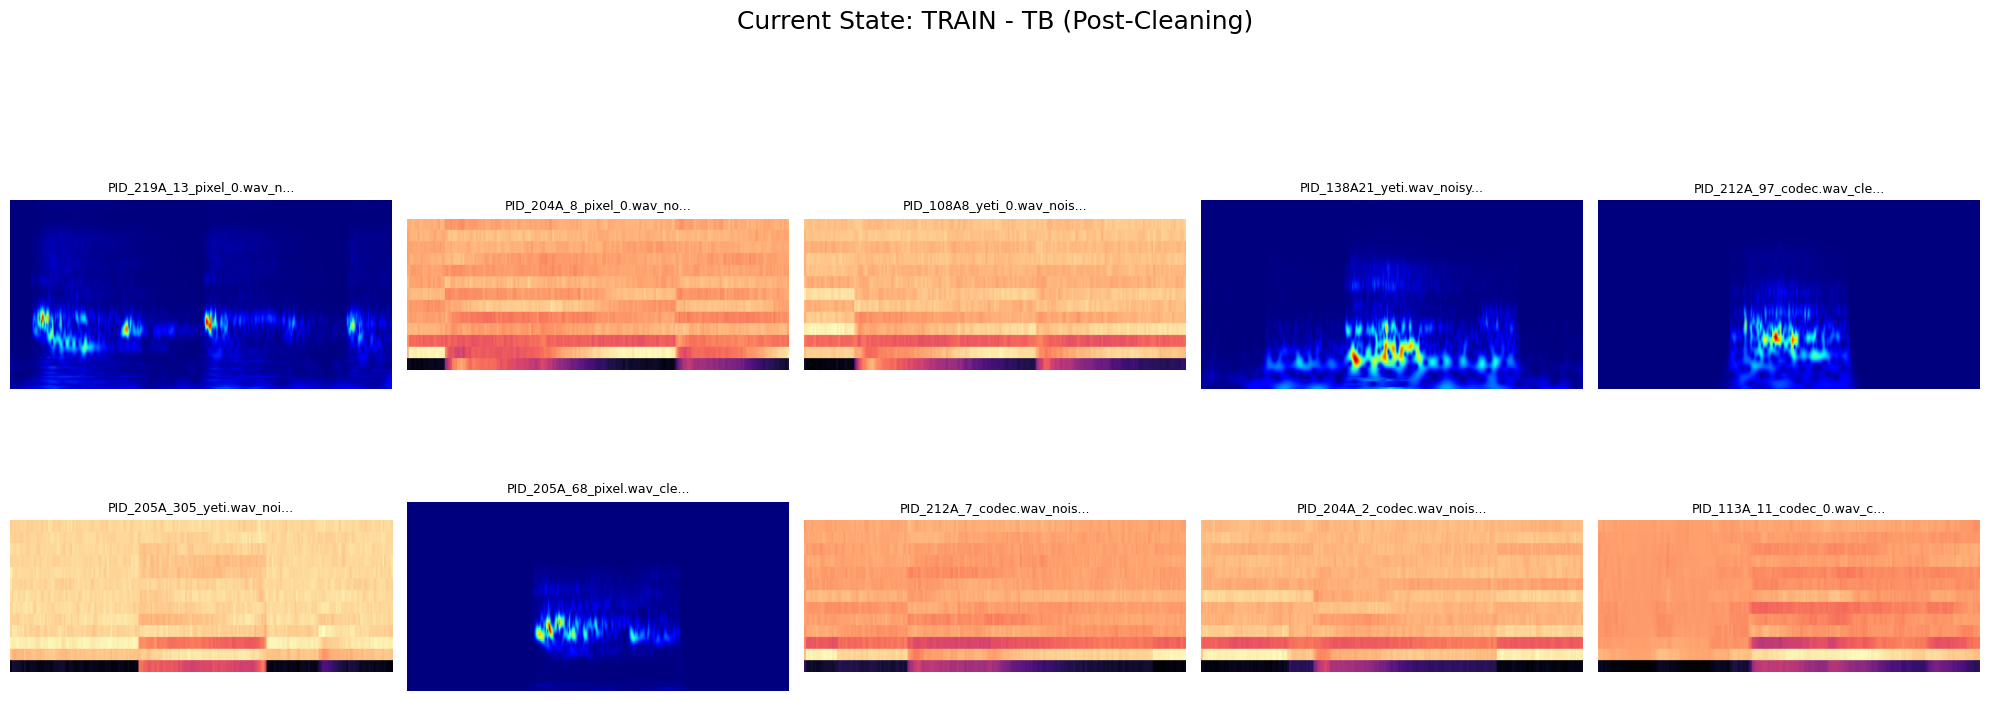

In [2]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

def plot_current_dataset(base_path, split='TRAIN', rows=2, cols=5):
    for class_name in ['Healthy', 'TB']:
        folder = os.path.join(base_path, split, class_name)
        
        # Filter hanya file gambar (.png atau .jpg)
        valid_ext = ('.png', '.jpg', '.jpeg')
        all_files = [f for f in os.listdir(folder) if f.lower().endswith(valid_ext)]
        
        if not all_files:
            print(f"⚠️ Folder {class_name} kosong atau tidak ada gambar!")
            continue

        num_samples = min(rows * cols, len(all_files))
        samples = random.sample(all_files, num_samples)
        
        fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
        fig.suptitle(f'Current State: {split} - {class_name} (Post-Cleaning)', fontsize=18, y=1.02)
        
        axes = axes.flatten()
        for i, file in enumerate(samples):
            img_path = os.path.join(folder, file)
            img = Image.open(img_path)
            axes[i].imshow(img)
            
            # Menampilkan label jenis fitur (MFCC/SCAL) dan varian (Clean/Noisy/Fast)
            # Contoh nama file: MFCC_FAST_PID_... atau MFCC_PID_..._clean.png
            axes[i].set_title(f"{file[:25]}...", fontsize=9)
            axes[i].axis('off')
        
        # Sembunyikan sisa grid jika sampel lebih sedikit dari grid
        for j in range(i + 1, len(axes)):
            axes[j].axis('off')

        plt.tight_layout()
        plt.show()

# Jalankan pengecekan untuk set TRAIN
plot_current_dataset(DATA_DIR, 'TRAIN')

🧐 Mengecek batch data Healthy...


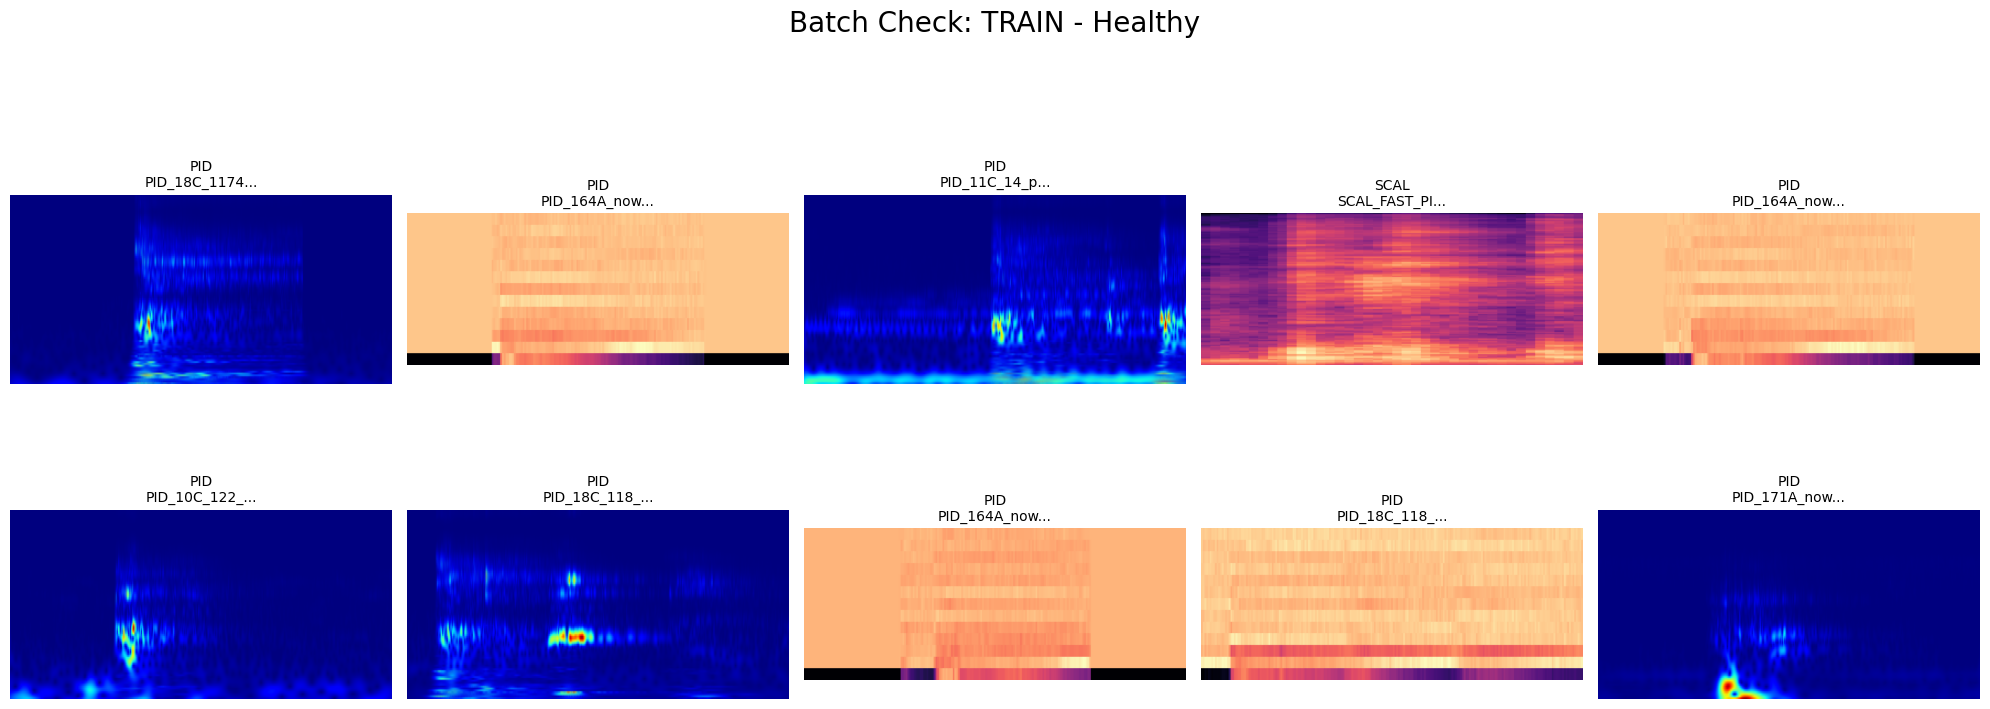

🧐 Mengecek batch data TB...


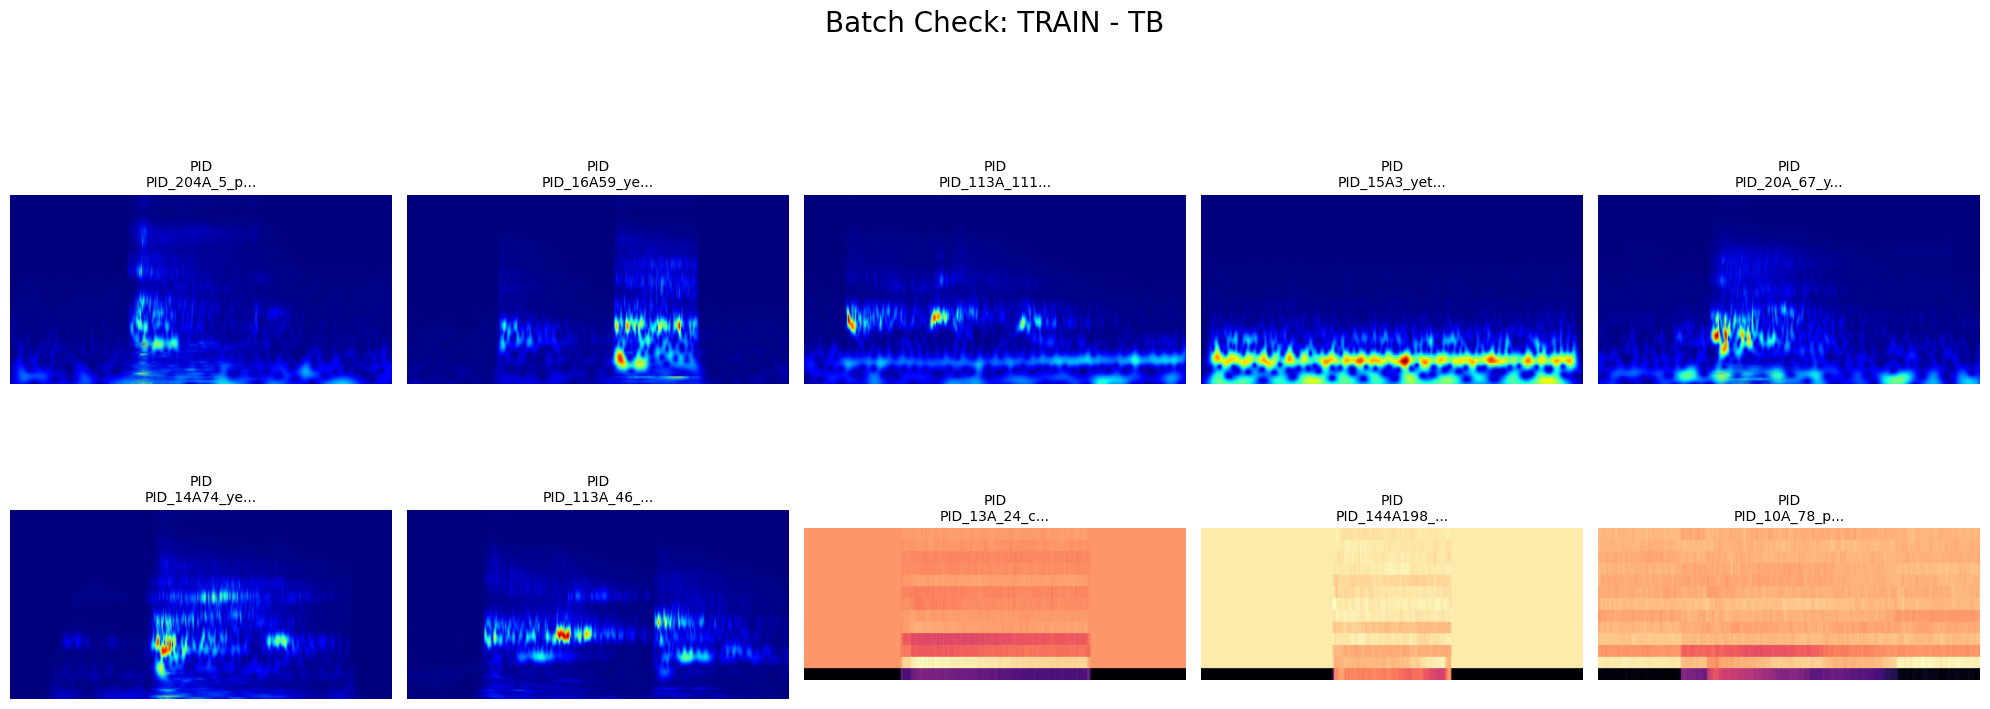

In [3]:
def plot_data_batch(base_path, split='TRAIN', class_name='Healthy', rows=2, cols=5):
    folder = os.path.join(base_path, split, class_name)
    num_samples = rows * cols
    
    # Filter hanya file gambar
    valid_ext = ('.png', '.jpg', '.jpeg')
    all_files = [f for f in os.listdir(folder) if f.lower().endswith(valid_ext)]
    
    if not all_files:
        print(f"⚠️ Tidak ada gambar di {folder}")
        return

    # Ambil sampel acak
    samples = random.sample(all_files, min(num_samples, len(all_files)))
    
    fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
    fig.suptitle(f'Batch Check: {split} - {class_name}', fontsize=20, y=1.02)
    
    axes = axes.flatten()
    for i, file in enumerate(samples):
        img_path = os.path.join(folder, file)
        img = Image.open(img_path)
        axes[i].imshow(img)
        # Menampilkan jenis augmentasi di judul gambar (PITCHUP, NOISY, dll)
        title_text = file.split('_')[0] if '_' in file else 'Original'
        if 'PITCHDOWN' in file: title_text = 'PITCHDOWN'
        if 'PITCHUP' in file: title_text = 'PITCHUP'
        
        axes[i].set_title(f"{title_text}\n{file[:12]}...", fontsize=10)
        axes[i].axis('off')
    
    # Menghapus sumbu jika jumlah gambar < jumlah grid
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

# --- CARA PAKAI ---
# Cek 10 data Healthy
print("🧐 Mengecek batch data Healthy...")
plot_data_batch(DATA_DIR, 'TRAIN', 'Healthy', rows=2, cols=5)

# Cek 10 data TB (Ganti 'TRAIN' jadi 'VAL' jika ingin cek data validasi)
print("🧐 Mengecek batch data TB...")
plot_data_batch(DATA_DIR, 'TRAIN', 'TB', rows=2, cols=5)

In [4]:
#Standarisasi Fitur MFCC: Mengubah Semua MFCC Menjadi Gambar yang Konsisten
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import librosa.display
from tqdm import tqdm

def standardize_mfcc_images(base_path):
    print("🚀 Memulai Standardisasi Fitur MFCC...")
    converted_count = 0
    
    for root, dirs, files in os.walk(base_path):
        for file in tqdm(files, desc=f"Processing {os.path.basename(root)}"):
            file_path = os.path.join(root, file)
            
            # 1. JIKA FILE ADALAH .PT (Data MFCC TB yang 'sembunyi')
            if file.endswith('_mfcc.pt'):
                mfcc_data = torch.load(file_path).numpy().squeeze()
                new_img_name = file.replace('_mfcc.pt', '_MFCC_FIX.png')
                save_path = os.path.join(root, new_img_name)
                
                # Simpan sebagai Gambar yang Bertekstur
                plt.figure(figsize=(10, 4))
                librosa.display.specshow(mfcc_data, cmap='magma')
                plt.axis('off')
                plt.savefig(save_path, bbox_inches='tight', pad_inches=0)
                plt.close()
                
                # Hapus file .pt aslinya agar folder bersih
                os.remove(file_path)
                converted_count += 1

            # 2. JIKA FILE ADALAH MFCC ORANYE (Data Healthy yang 'salah kostum')
            # Kita tandai dengan nama file yang mengandung 'MFCC' dan ekstensinya '.png'
            elif 'MFCC' in file.upper() and file.endswith('.png') and 'FIX' not in file:
                # Untuk yang ini, sebaiknya kita hapus saja yang oranye
                # Nanti MobileNetV2 akan belajar dari Scalogram dan MFCC-FIX yang baru
                os.remove(file_path)
                
    print(f"\n✨ BERES! Berhasil menstandarisasi {converted_count} fitur MFCC.")

# Jalankan Standardisasi
standardize_mfcc_images(DATA_DIR)

🚀 Memulai Standardisasi Fitur MFCC...


Processing RespiScan_Train_Ready: 0it [00:00, ?it/s]
Processing test: 0it [00:00, ?it/s]
Processing TB: 100%|██████████| 380/380 [00:00<00:00, 140413.67it/s]
Processing train: 0it [00:00, ?it/s]
Processing TB: 100%|██████████| 1908/1908 [00:00<00:00, 236020.06it/s]
Processing val: 0it [00:00, ?it/s]
Processing TB: 100%|██████████| 536/536 [00:00<00:00, 175870.06it/s]


✨ BERES! Berhasil menstandarisasi 0 fitur MFCC.


🔎 Mengecek hasil standardisasi MFCC di set TRAIN...


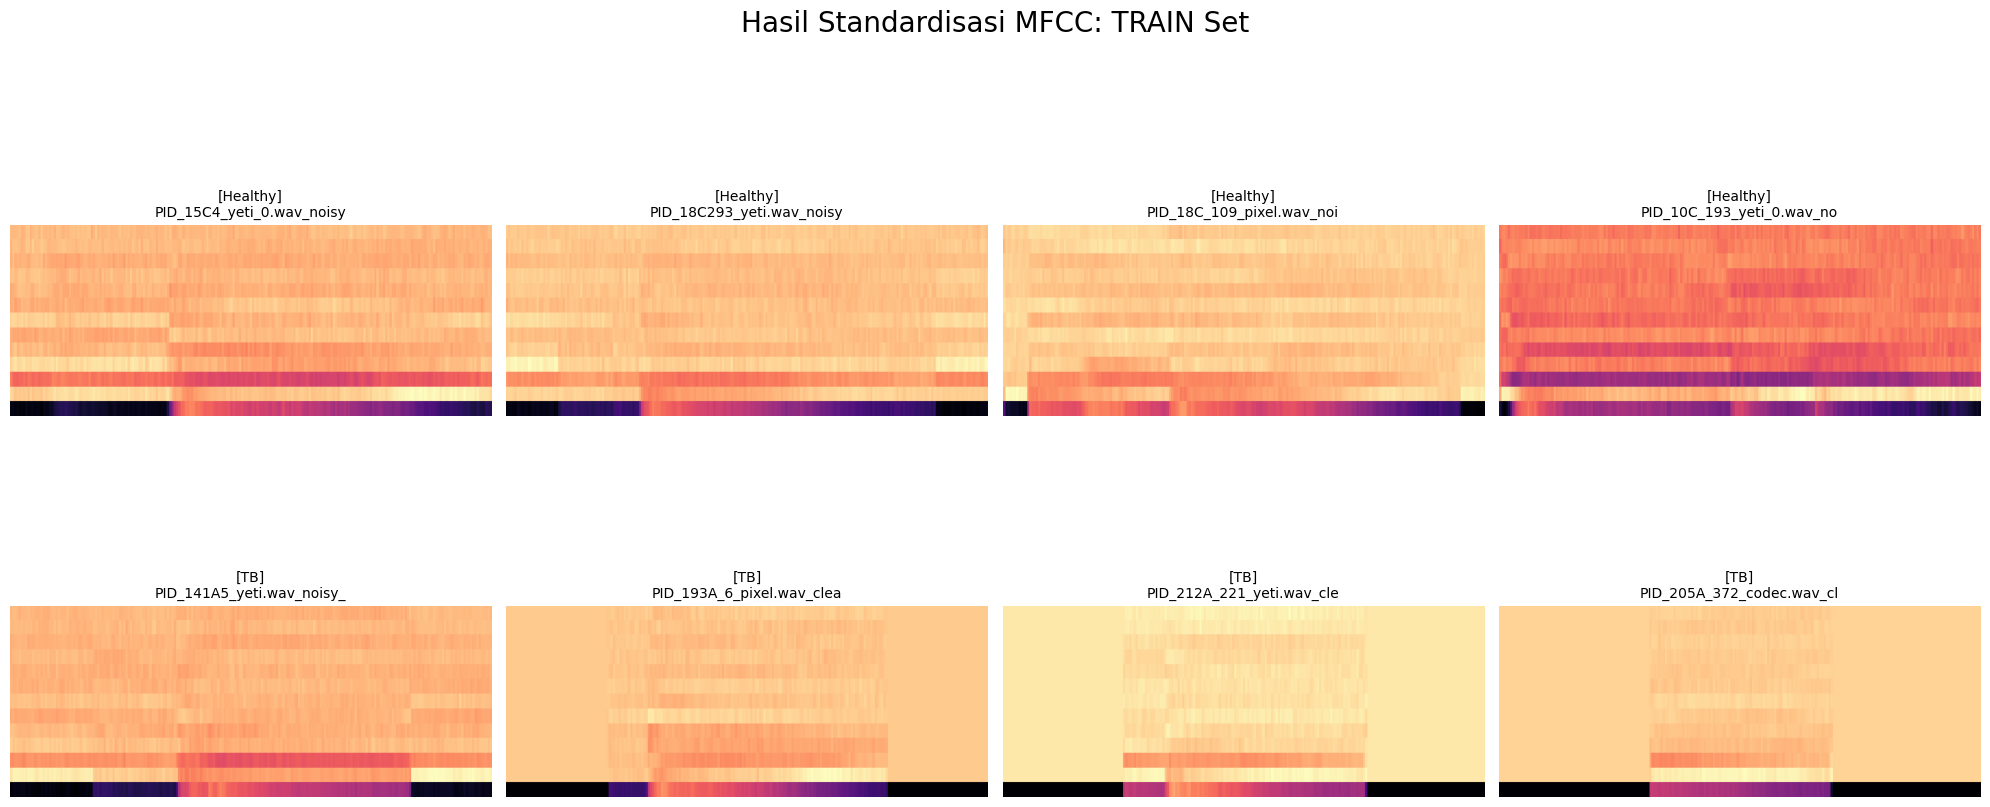

In [5]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

def check_new_mfcc(base_path, split='TRAIN', rows=2, cols=4):
    print(f"🔎 Mengecek hasil standardisasi MFCC di set {split}...")
    
    # List untuk menampung gambar MFCC dari kedua kelas
    mfcc_images = []
    
    for class_name in ['Healthy', 'TB']:
        folder = os.path.join(base_path, split, class_name)
        if not os.path.exists(folder): continue
        
        # Cari file yang mengandung kata 'MFCC' dan berakhiran .png
        files = [os.path.join(folder, f) for f in os.listdir(folder) 
                 if 'MFCC' in f.upper() and f.lower().endswith('.png')]
        
        # Ambil sampel acak dari kelas ini
        samples = random.sample(files, min(len(files), (rows * cols) // 2))
        for s in samples:
            mfcc_images.append((s, class_name))

    if not mfcc_images:
        print("⚠️ Belum ada gambar MFCC. Pastikan script standardisasi sudah dijalankan!")
        return

    # Tampilkan dalam Grid
    fig, axes = plt.subplots(rows, cols, figsize=(20, 10))
    fig.suptitle(f'Hasil Standardisasi MFCC: {split} Set', fontsize=20)
    axes = axes.flatten()

    for i, (img_path, label) in enumerate(mfcc_images):
        if i >= len(axes): break
        img = Image.open(img_path)
        axes[i].imshow(img)
        # Tampilkan nama file dan labelnya
        file_name = os.path.basename(img_path)
        axes[i].set_title(f"[{label}]\n{file_name[:25]}", fontsize=10)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

# Jalankan pengecekan
check_new_mfcc(DATA_DIR)

In [8]:
#UNDERSAMPLING
import os
import random
import shutil

def balance_dataset_undersampling(base_path, backup_path):
    print("⚖️ Memulai proses Undersampling untuk menyeimbangkan data...")
    
    for split in ['TRAIN', 'VAL', 'TEST']:
        healthy_dir = os.path.join(base_path, split, 'Healthy')
        tb_dir = os.path.join(base_path, split, 'TB')
        
        if not os.path.exists(healthy_dir) or not os.path.exists(tb_dir):
            print(f"⚠️ Folder untuk {split} tidak lengkap, melewati...")
            continue
            
        # Ambil daftar file gambar
        healthy_files = [f for f in os.listdir(healthy_dir) if f.lower().endswith(('.png', '.jpg'))]
        tb_files = [f for f in os.listdir(tb_dir) if f.lower().endswith(('.png', '.jpg'))]
        
        n_healthy = len(healthy_files)
        n_tb = len(tb_files)
        
        print(f"\n📁 Analisis {split}: Healthy ({n_healthy}) vs TB ({n_tb})")
        
        if n_tb > n_healthy:
            # Hitung selisihnya
            n_to_move = n_tb - n_healthy
            # Pilih file TB secara acak untuk dipindahkan
            files_to_move = random.sample(tb_files, n_to_move)
            
            # Siapkan folder backup agar data tidak hilang permanen
            current_backup_dir = os.path.join(backup_path, split, 'TB_unused')
            os.makedirs(current_backup_dir, exist_ok=True)
            
            for f in files_to_move:
                src = os.path.join(tb_dir, f)
                dst = os.path.join(current_backup_dir, f)
                shutil.move(src, dst)
                
            print(f"✅ Berhasil meratakan! {n_to_move} file TB dipindahkan ke backup.")
            print(f"✨ Hasil Akhir {split}: Healthy = {n_healthy}, TB = {n_healthy}")
        else:
            print(f"ℹ️ Set {split} sudah seimbang atau data Healthy lebih banyak.")

# Tentukan lokasi backup (Ganti jika ingin di folder lain)
BACKUP_PATH = r'C:\TBC SCREENING PENELITIAN\Dataset_Unused_Backup'

# EKSEKUSI
balance_dataset_undersampling(DATA_DIR, BACKUP_PATH)

⚖️ Memulai proses Undersampling untuk menyeimbangkan data...

📁 Analisis TRAIN: Healthy (1908) vs TB (1908)
ℹ️ Set TRAIN sudah seimbang atau data Healthy lebih banyak.

📁 Analisis VAL: Healthy (536) vs TB (536)
ℹ️ Set VAL sudah seimbang atau data Healthy lebih banyak.

📁 Analisis TEST: Healthy (380) vs TB (380)
ℹ️ Set TEST sudah seimbang atau data Healthy lebih banyak.


In [31]:
import os

def audit_dataset(target_path):
    print("📊 Audit Dataset Setelah Pembersihan:")
    for split in ['TRAIN', 'VAL', 'TEST']:
        print(f"📁 Set: {split.upper()}")
        for label in ['Healthy', 'TB']:
            path = os.path.join(target_path, split, label)
            if os.path.exists(path):
                # Hitung hanya file gambar
                n_files = len([f for f in os.listdir(path) if f.lower().endswith(('.png', '.jpg'))])
                print(f"   - {label}: {n_files} gambar")
        print("-" * 30)

audit_dataset(DATA_DIR)

📊 Audit Dataset Setelah Pembersihan:
📁 Set: TRAIN
   - Healthy: 1908 gambar
   - TB: 1908 gambar
------------------------------
📁 Set: VAL
   - Healthy: 536 gambar
   - TB: 536 gambar
------------------------------
📁 Set: TEST
   - Healthy: 380 gambar
   - TB: 380 gambar
------------------------------


In [7]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os

# 1. Definisi Transform yang BENAR-BENAR BERSIH
# Kita pakai Resize standar tanpa potong (Crop) agar tidak ada area hitam
clean_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)), # Paksa ukuran ke 224x224 tanpa memotong
        transforms.RandomHorizontalFlip(p=0.5), # Hanya balik kiri-kanan (waktu)
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# 2. Paksa Re-inisialisasi Dataset dan Loader
# Pastikan DATA_DIR merujuk ke folder dataset kamu yang sudah bersih
image_datasets = {
    x: datasets.ImageFolder(os.path.join(DATA_DIR, x.upper()), clean_transforms[x])
    for x in ['train', 'val']
}

dataloaders = {
    x: DataLoader(image_datasets[x], batch_size=32, shuffle=True, num_workers=0)
    for x in ['train', 'val']
}

print("🧹 DataLoader telah di-reset total! Harusnya sudah tegak lurus dan tanpa area hitam.")

🧹 DataLoader telah di-reset total! Harusnya sudah tegak lurus dan tanpa area hitam.


In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# 1. Load Pretrained ResNet18
model = models.resnet18(weights='DEFAULT')

# 2. Unfreeze semua layer untuk Fine-Tuning
for param in model.parameters():
    param.requires_grad = True

# 3. Modifikasi Classifier (Sesuai paper TBscreen: 2 dense layer + Dropout)
num_ftrs = model.fc.in_features
model.fc = nn.Sequential(
    nn.Linear(num_ftrs, 512),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(512, 2)
    # Catatan: Kita tidak pakai Sigmoid di ujung karena nn.CrossEntropyLoss sudah merangkap Softmax secara internal.
)

model = model.to(DEVICE)

# 4. Optimizer dengan Differential Learning Rate untuk ResNet18
# Kita buat layer paling atas (layer4) belajar sangat pelan, dan classifier belajar normal
optimizer = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-5},
    {'params': model.fc.parameters(), 'lr': 1e-4}
], lr=1e-5) # Layer dasar sisanya (layer1-3) menggunakan LR sangat kecil jika ikut terupdate

# 5. Weighted Cross Entropy Loss (Hukuman 2x lipat jika salah menebak Healthy)
weights = torch.tensor([2.0, 1.0]).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=weights)

print("✅ Model diganti ke ResNet18! Unfreezing + Weighted Loss + Differential LR siap digunakan.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Gibran/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:03<00:00, 12.4MB/s]


✅ Model diganti ke ResNet18! Unfreezing + Weighted Loss + Differential LR siap digunakan.


In [9]:
import torch
import torch.nn as nn
from torchvision import models
import time
import copy
from sklearn.metrics import f1_score
from torch.optim.lr_scheduler import ReduceLROnPlateau

# ==========================================
# 1. SETUP MODEL MOBILENETV2 (V7)
# ==========================================
model = models.mobilenet_v2(weights='DEFAULT')

# Unfreeze semua layer agar bisa dikalibrasi
for param in model.parameters():
    param.requires_grad = True

# Ganti Classifier (Beri Dropout 0.5 untuk cegah overfit)
num_ftrs = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Linear(num_ftrs, 512),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(512, 2)
)

model = model.to(DEVICE)

# Optimizer dengan Differential Learning Rates
optimizer = torch.optim.Adam([
    {'params': model.features[14:].parameters(), 'lr': 1e-5}, # Layer atas belajar pelan
    {'params': model.classifier.parameters(), 'lr': 1e-4}      # Classifier belajar normal
], lr=1e-4)

# Weighted Loss (Bobot 2:1 untuk memaksa model fokus ke kelas Healthy)
weights = torch.tensor([2.0, 1.0]).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=weights)

print("✅ Setup MobileNetV2 Selesai! Unfreezing + Weighted Loss + Differential LR siap.")


# ==========================================
# 2. FUNGSI TRAINING DENGAN EARLY STOPPING
# ==========================================
def train_model_v4(model, criterion, optimizer, num_epochs=25, patience=7):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_f1 = 0.0
    early_stop_counter = 0
    
    # Scheduler untuk mengecilkan LR otomatis saat akurasi mentok
    scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)
    
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_f1': []}

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train': model.train()
            else: model.eval()

            running_loss, running_corrects = 0.0, 0
            all_preds, all_labels = [], []

            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

            epoch_loss = running_loss / len(image_datasets[phase])
            epoch_acc = running_corrects.double() / len(image_datasets[phase])
            epoch_f1 = f1_score(all_labels, all_preds, zero_division=0)

            print(f'{phase.upper()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f} F1: {epoch_f1:.4f}')

            if phase == 'train':
                history['train_loss'].append(epoch_loss)
                history['train_acc'].append(epoch_acc.item())
            else:
                history['val_loss'].append(epoch_loss)
                history['val_acc'].append(epoch_acc.item())
                history['val_f1'].append(epoch_f1)
                
                # Update Scheduler berdasarkan Val F1
                scheduler.step(epoch_f1)

                if epoch_f1 > best_f1:
                    best_f1 = epoch_f1
                    best_model_wts = copy.deepcopy(model.state_dict())
                    torch.save(model.state_dict(), 'best_RespiScan_MobileNetV2.pth')
                    early_stop_counter = 0
                    print("⭐️ Model Terbaik Disimpan!")
                else:
                    early_stop_counter += 1

        if early_stop_counter >= patience:
            print(f"🛑 Early Stopping di epoch {epoch+1}")
            break
        print()

    model.load_state_dict(best_model_wts)
    return model, history

# ==========================================
# 3. MULAI TRAINING
# ==========================================
model_trained, history = train_model_v4(model, criterion, optimizer, num_epochs=30)

✅ Setup MobileNetV2 Selesai! Unfreezing + Weighted Loss + Differential LR siap.
Epoch 1/30
----------
TRAIN Loss: 0.5433 Acc: 0.5676 F1: 0.3750
VAL Loss: 0.6172 Acc: 0.6035 F1: 0.5405
⭐️ Model Terbaik Disimpan!

Epoch 2/30
----------
TRAIN Loss: 0.4877 Acc: 0.6478 F1: 0.5712
VAL Loss: 0.5957 Acc: 0.5709 F1: 0.3931

Epoch 3/30
----------
TRAIN Loss: 0.4637 Acc: 0.6751 F1: 0.6101
VAL Loss: 0.6262 Acc: 0.6119 F1: 0.6008
⭐️ Model Terbaik Disimpan!

Epoch 4/30
----------
TRAIN Loss: 0.4425 Acc: 0.7204 F1: 0.6779
VAL Loss: 0.6547 Acc: 0.6213 F1: 0.6413
⭐️ Model Terbaik Disimpan!

Epoch 5/30
----------
TRAIN Loss: 0.4181 Acc: 0.7369 F1: 0.7026
VAL Loss: 0.6392 Acc: 0.6157 F1: 0.5838

Epoch 6/30
----------
TRAIN Loss: 0.4008 Acc: 0.7586 F1: 0.7313
VAL Loss: 0.6586 Acc: 0.6474 F1: 0.6434
⭐️ Model Terbaik Disimpan!

Epoch 7/30
----------
TRAIN Loss: 0.3857 Acc: 0.7762 F1: 0.7529
VAL Loss: 0.6360 Acc: 0.6353 F1: 0.6047

Epoch 8/30
----------
TRAIN Loss: 0.3704 Acc: 0.7864 F1: 0.7665
VAL Loss: 0.7

KeyboardInterrupt: 


📊 Classification Report:
              precision    recall  f1-score   support

     Healthy       0.86      0.53      0.65       380
          TB       0.66      0.91      0.76       380

    accuracy                           0.72       760
   macro avg       0.76      0.72      0.71       760
weighted avg       0.76      0.72      0.71       760



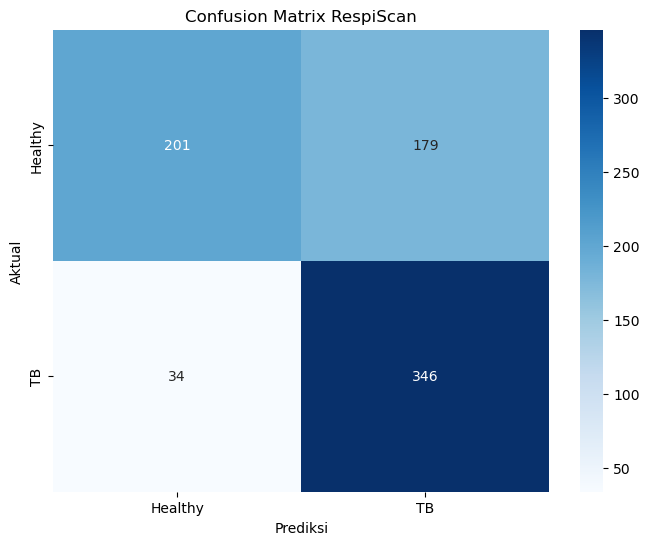

In [24]:
from sklearn.metrics import classification_report

def evaluate_final(model, test_loader):
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(DEVICE)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    # Classification Report
    print("\n📊 Classification Report:")
    print(classification_report(all_labels, all_preds, target_names=class_names))
    
    # Confusion Matrix Visualization
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.title('Confusion Matrix RespiScan')
    plt.show()

# Jalankan evaluasi pada data TEST
# Pastikan kamu buat test_loader dulu jika belum ada (mirip Blok 3 tapi folder TEST)
test_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, 'TEST'), data_transforms['val'])
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

evaluate_final(model_trained, test_loader)

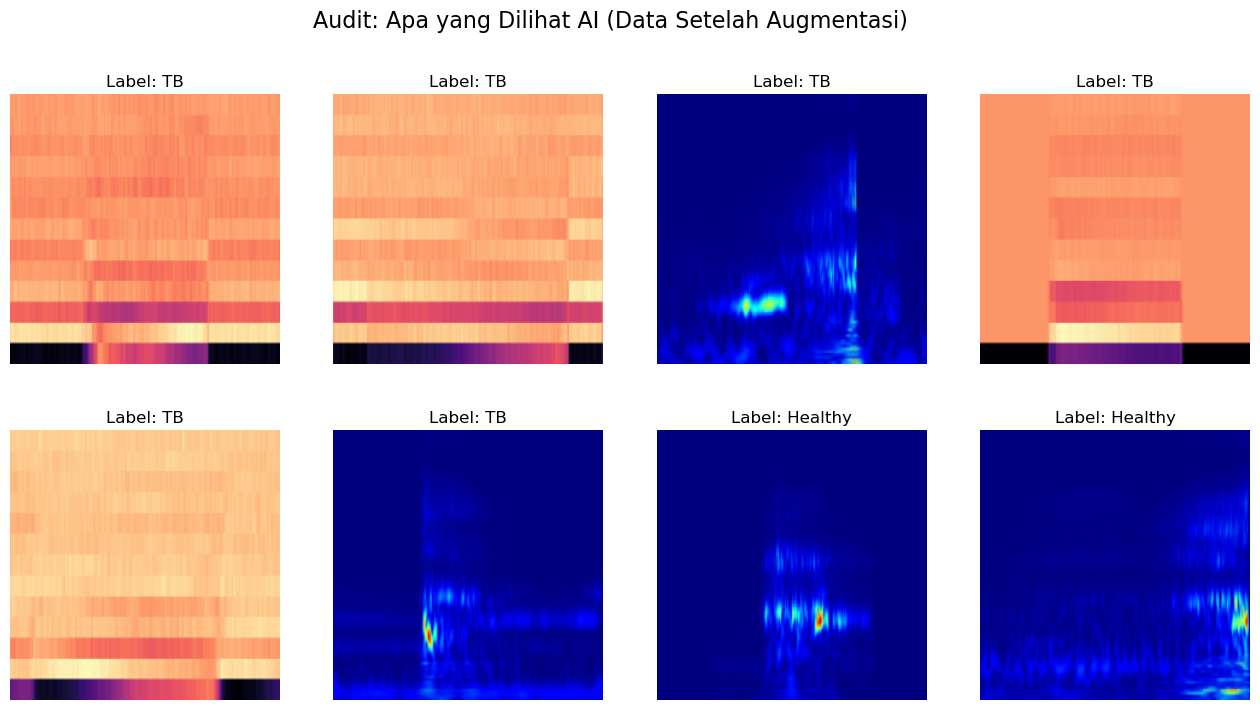

In [30]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_augmented_data(dataloader, class_names):
    # Ambil satu batch data
    inputs, classes = next(iter(dataloader))
    
    fig = plt.figure(figsize=(16, 8))
    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)
        # Un-normalize untuk visualisasi
        img = inputs[i].numpy().transpose((1, 2, 0))
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)
        
        plt.imshow(img)
        ax.set_title(f'Label: {class_names[classes[i]]}')
        ax.axis('off')
    
    plt.suptitle("Audit: Apa yang Dilihat AI (Data Setelah Augmentasi)", fontsize=16)
    plt.show()

# Jalankan audit visual pada dataloader 'train'
visualize_augmented_data(dataloaders['train'], class_names)

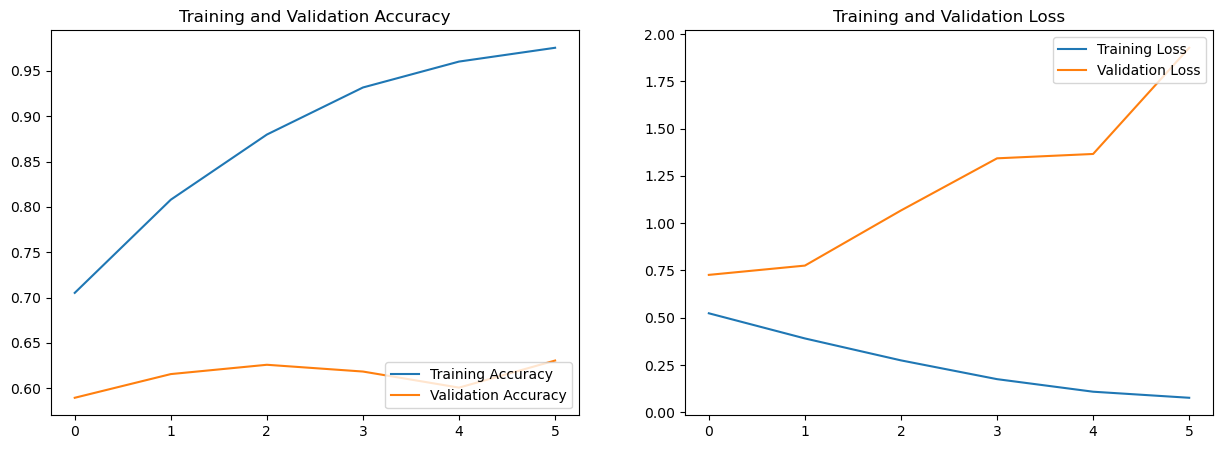

In [15]:
import matplotlib.pyplot as plt

def plot_history(history):
    acc = history['train_acc']
    val_acc = history['val_acc']
    loss = history['train_loss']
    val_loss = history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(15, 5))
    
    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend(loc='lower right')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.legend(loc='upper right')
    
    plt.show()

plot_history(history)